# **Keyword evaluation Strategies**

In the notebook of creating collection we used a chunk size of 1000 and overlap of 500, and we tested our strategies but it wasn't sufficient.

To enhance that we will evaluate on different chunk size and ovelap to see if we can extract the best retreival performance

## **Getting the data**

In [1]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import BertTokenizer
from rank_bm25 import BM25Okapi
import chromadb
from pathlib import Path

tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-cased')

In [2]:
db_path = Path(".").resolve().parent / "Collections"
client = chromadb.PersistentClient(path=db_path)

In [3]:
collection = client.get_collection(
    name="jurisprudence_chunk_100_overlap_40"
)

In [4]:
def get_all_documents(collection, batch_size=500):
    documents = []
    ids = []
    metadatas = []
    offset = 0

    while True:
        batch = collection.get(
            limit=batch_size,
            offset=offset,
            include=["documents", "metadatas"],
        )

        batch_ids = batch["ids"]
        batch_documents = batch["documents"] or []
        batch_metadatas = batch["metadatas"] or []

        if not batch_ids:
            break

        if not (
            len(batch_ids)
            == len(batch_documents)
            == len(batch_metadatas)
        ):
            raise ValueError(
                "Chroma returned misaligned documents, IDs, and metadata"
            )

        ids.extend(batch_ids)
        documents.extend(batch_documents)
        metadatas.extend(batch_metadatas)

        offset += len(batch_ids)

    if not documents:
        raise ValueError("The Chroma collection contains no documents")

    return {
        "documents": documents,
        "ids": ids,
        "metadatas": metadatas,
    }

In [5]:
import json
from pathlib import Path

file_path = db_path = Path(".").resolve().parent / "Retreival" / "keyword_evaluation.json"
if file_path is None:
    raise FileNotFoundError(
        "keyword_evaluation.json was not found from the current working directory"
    )

with file_path.open(encoding="utf-8") as file:
    evaluation_data = json.load(file)

queries = evaluation_data["queries"]

In [6]:
from Retreival.KeywordSearch import evaluate_strategy, KeywordSearch_TFIDF, KeywordSearch_BM25

In [7]:
def evaluate_search(
        search_function,
        method_name, 
        evaluation_queries, 
        collection_names = [
            "jurisprudence_chunk_100_overlap_40", 
            "jurisprudence_chunk_300_overlap_140", 
            "jurisprudence_chunk_500_overlap_240"
        ],
        ):
    results = []

    for collection_name in collection_names:
        # Evaluate the search function on the current collection
        collection = client.get_collection(name=collection_name)

        keyword_index = get_all_documents(collection)

        keyword_index["tfidf_vectorizer"] = TfidfVectorizer()
        
        keyword_index["tfidf_vectors"] = keyword_index["tfidf_vectorizer"].fit_transform(
            keyword_index["documents"]
        )
        keyword_index["bm25_tokens"] = tokenizer(
            keyword_index["documents"],
            add_special_tokens=False,
            truncation=False,
        )["input_ids"]
        keyword_index["bm25_index"] = BM25Okapi(
            keyword_index["bm25_tokens"],
            k1=1.25,
        )
        
        print(f"Indexes built for {len(keyword_index['documents'])} chunks")
        summary_tf_idf, per_query_tf_idf = evaluate_strategy(search_function, method_name, evaluation_queries, keyword_index)

        res = {
            "collection_name": collection_name,
            "method_name": method_name,
            "summary": summary_tf_idf,
            "per_query": per_query_tf_idf,
        }
        results.append(res)

    return results

## **Evaluation**

### **Keyword search TF-IDF**

In [8]:
results_tf_idf = evaluate_search(KeywordSearch_TFIDF, "TF-IDF", queries)

Indexes built for 103688 chunks
Indexes built for 38976 chunks
Indexes built for 23946 chunks


In [9]:
for r in results_tf_idf:
    print(f"Collection: {r['collection_name']}, Method: {r['method_name']}")
    print(f"Summary: {r['summary']}")

Collection: jurisprudence_chunk_100_overlap_40, Method: TF-IDF
Summary: {'method': 'TF-IDF', 'queries': 15, 'precision@2': 0.3, 'recall@2': 0.3138888888888889, 'ndcg@2': 0.4, 'precision@5': 0.18666666666666668, 'recall@5': 0.4166666666666667, 'ndcg@5': 0.41191980014970986, 'precision@10': 0.12000000000000001, 'recall@10': 0.49444444444444446, 'ndcg@10': 0.43060971860643343}
Collection: jurisprudence_chunk_300_overlap_140, Method: TF-IDF
Summary: {'method': 'TF-IDF', 'queries': 15, 'precision@2': 0.23333333333333334, 'recall@2': 0.2777777777777778, 'ndcg@2': 0.3075431461843639, 'precision@5': 0.18666666666666668, 'recall@5': 0.4583333333333333, 'ndcg@5': 0.4019411745342846, 'precision@10': 0.12000000000000001, 'recall@10': 0.5416666666666666, 'ndcg@10': 0.4360853282368135}
Collection: jurisprudence_chunk_500_overlap_240, Method: TF-IDF
Summary: {'method': 'TF-IDF', 'queries': 15, 'precision@2': 0.26666666666666666, 'recall@2': 0.34444444444444444, 'ndcg@2': 0.3496051297557944, 'precisio

In [12]:
for r in results_tf_idf:
    print(f"Collection: {r['collection_name']}, Method: {r['method_name']}")
    print(f"detailled: {r['per_query']}")

Collection: jurisprudence_chunk_100_overlap_40, Method: TF-IDF
detailled: [{'method': 'TF-IDF', 'query_id': 'q01', 'query': 'Je cherche des affaires liées à la résiliation d’un contrat de travail.', 'retrieved_source_ids': ['6253c844bd3db21cbdd84be2', '65876a8011b7b1b261cb1a28', '6253c84abd3db21cbdd84cce', '65b0127cb98137c17478d2d6', '658096ec3ea7c8c1120de1c6', '65876a7f11b7b1b261cb1a10', '659851a0b972daea122dcc70', '6253c844bd3db21cbdd84c04', '659851a3b972daea122dd08b', '6253c845bd3db21cbdd84c2f'], 'precision@2': 0.0, 'recall@2': 0.0, 'ndcg@2': 0.0, 'precision@5': 0.0, 'recall@5': 0.0, 'ndcg@5': 0.0, 'precision@10': 0.1, 'recall@10': 0.08333333333333333, 'ndcg@10': 0.06362078819895171}, {'method': 'TF-IDF', 'query_id': 'q02', 'query': 'Quelles décisions concernent un licenciement pour faute grave ?', 'retrieved_source_ids': ['6253c84abd3db21cbdd84ccd', '6253c845bd3db21cbdd84c32', '6253c84abd3db21cbdd84cce', '65876a7f11b7b1b261cb1a0d', '6581ee053ea7c8c112520e5d', '6253c83cbd3db21cbdd84

### **Keyword search BM25**

In [10]:
results_keyword_bm25 = evaluate_search(KeywordSearch_BM25, "BM25", queries)

Indexes built for 103688 chunks
Indexes built for 38976 chunks
Indexes built for 23946 chunks


In [16]:
for r in results_keyword_bm25:
    print(f"Collection: {r['collection_name']}, Method: {r['method_name']}")
    print(f"Summary: {r['summary']}")

Collection: jurisprudence_chunk_100_overlap_40, Method: BM25
Summary: {'method': 'BM25', 'queries': 15, 'precision@2': 0.3, 'recall@2': 0.36666666666666664, 'ndcg@2': 0.3904816092734916, 'precision@5': 0.18666666666666668, 'recall@5': 0.4888888888888889, 'ndcg@5': 0.4361743151005011, 'precision@10': 0.12666666666666668, 'recall@10': 0.5694444444444444, 'ndcg@10': 0.4766371285348305}
Collection: jurisprudence_chunk_300_overlap_140, Method: BM25
Summary: {'method': 'BM25', 'queries': 15, 'precision@2': 0.3333333333333333, 'recall@2': 0.3888888888888889, 'ndcg@2': 0.41627179642246104, 'precision@5': 0.18666666666666668, 'recall@5': 0.4888888888888889, 'ndcg@5': 0.44381032299573525, 'precision@10': 0.12, 'recall@10': 0.5888888888888889, 'ndcg@10': 0.488427711042385}
Collection: jurisprudence_chunk_500_overlap_240, Method: BM25
Summary: {'method': 'BM25', 'queries': 15, 'precision@2': 0.36666666666666664, 'recall@2': 0.35, 'ndcg@2': 0.42579018714896943, 'precision@5': 0.18666666666666668, '

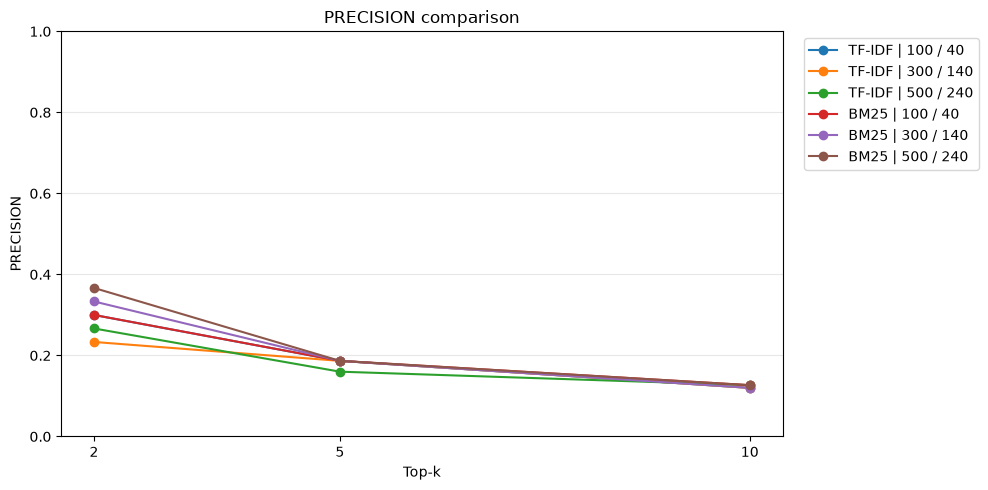

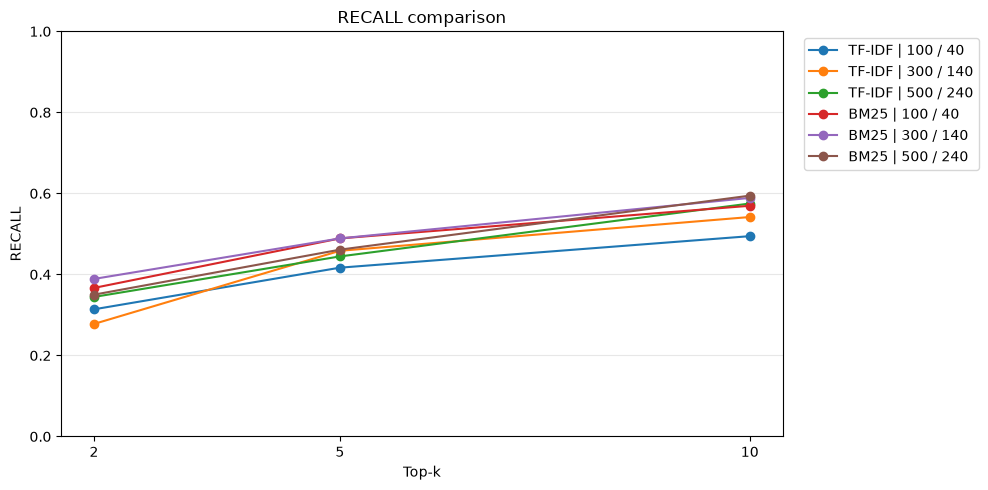

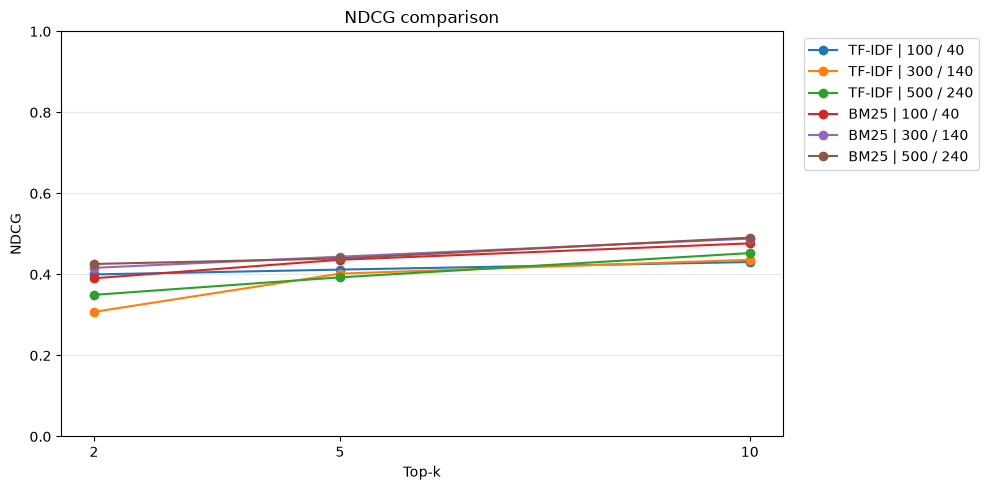

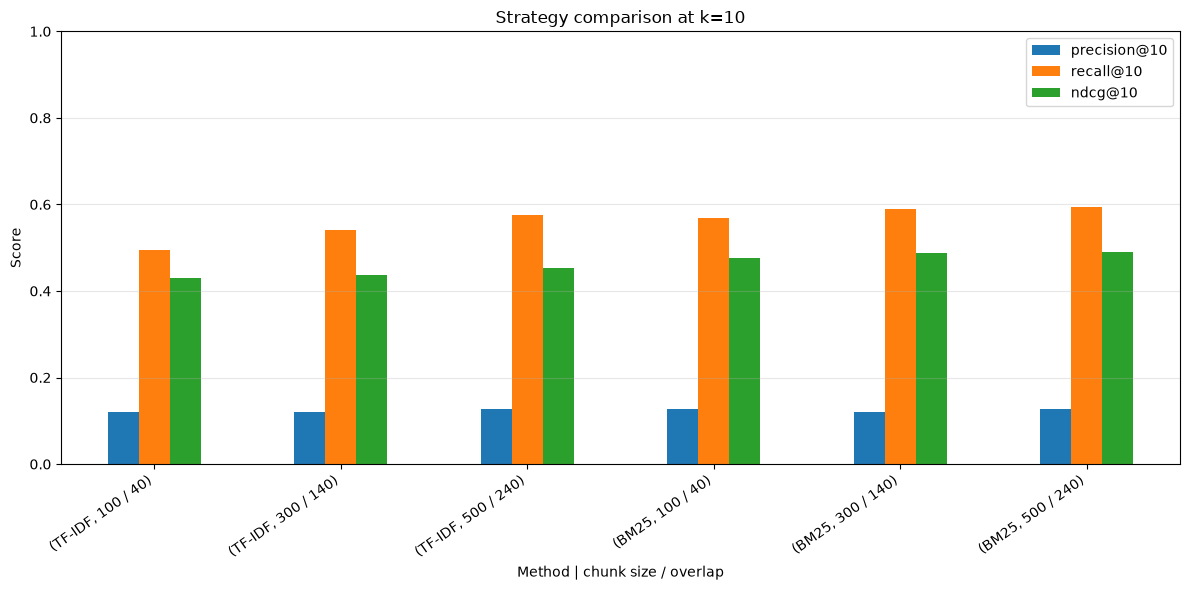

method  chunking  precision@10  recall@10  ndcg@10
  BM25 500 / 240      0.126667   0.594444 0.490841
  BM25 300 / 140      0.120000   0.588889 0.488428
  BM25  100 / 40      0.126667   0.569444 0.476637
TF-IDF 500 / 240      0.126667   0.575000 0.452701
TF-IDF 300 / 140      0.120000   0.541667 0.436085
TF-IDF  100 / 40      0.120000   0.494444 0.430610


In [18]:

import pandas as pd
import matplotlib.pyplot as plt
import re

# --------------------------------------------------
# 1. Convert the evaluation results into one DataFrame
# --------------------------------------------------

def build_comparison_dataframe(*results_groups):
    rows = []

    for results in results_groups:
        for result in results:
            summary = result["summary"]

            # Extract chunk size and overlap from collection name
            match = re.search(
                r"chunk_(\d+)_overlap_(\d+)",
                result["collection_name"]
            )

            chunking = (
                f"{match.group(1)} / {match.group(2)}"
                if match else result["collection_name"]
            )

            row = {
                "method": result["method_name"],
                "collection": result["collection_name"],
                "chunking": chunking,
                **summary,
            }
            rows.append(row)

    return pd.DataFrame(rows)


df = build_comparison_dataframe(
    results_tf_idf,
    results_keyword_bm25,
)

# --------------------------------------------------
# 2. Compare all strategies for each metric
# --------------------------------------------------

metrics = ["precision", "recall", "ndcg"]
cutoffs = [2, 5, 10]

for metric in metrics:
    fig, ax = plt.subplots(figsize=(10, 5))

    for _, row in df.iterrows():
        values = [row[f"{metric}@{k}"] for k in cutoffs]
        label = f'{row["method"]} | {row["chunking"]}'

        ax.plot(cutoffs, values, marker="o", label=label)

    ax.set_title(f"{metric.upper()} comparison")
    ax.set_xlabel("Top-k")
    ax.set_ylabel(metric.upper())
    ax.set_xticks(cutoffs)
    ax.set_ylim(0, 1)
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    plt.show()

# --------------------------------------------------
# 3. Compare strategies at k=10
# --------------------------------------------------

metrics_at_10 = ["precision@10", "recall@10", "ndcg@10"]

plot_df = df.set_index(["method", "chunking"])[metrics_at_10]

ax = plot_df.plot(kind="bar", figsize=(12, 6))
ax.set_title("Strategy comparison at k=10")
ax.set_xlabel("Method | chunk size / overlap")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. Rank the strategies by nDCG@10
# --------------------------------------------------

ranking = df.sort_values(
    ["ndcg@10", "recall@10"],
    ascending=False
)

print(
    ranking[
        ["method", "chunking",
         "precision@10", "recall@10", "ndcg@10"]
    ].to_string(index=False)
)
